# Assignment: Data Wrangling

### Reading material: `tidy_data.pdf`

**Q1.** This question provides some practice cleaning variables which have common problems.
1. For `./data/airbnb_hw.csv`, clean the `Price` variable as well as you can, and explain the choices you make. How many missing values do you end up with? (Hint: What happens to the formatting when a price goes over 999 dollars, say from 675 to 1,112?)
2. For the Minnesota police use of for data, `./data/mn_police_use_of_force.csv`, clean the `subject_injury` variable, handling the NA's; this gives a value `Yes` when a person was injured by police, and `No` when no injury occurred. What proportion of the values are missing? Is this a concern? Cross-tabulate your cleaned `subject_injury` variable with the `force_type` variable. Are there any patterns regarding when the data are missing?

**Q2.** Go to https://sharkattackfile.net/ and download their dataset on shark attacks (Hint: `GSAF5.xls`).

1. Open the shark attack file using Pandas. It is probably not a csv file, so `read_csv` won't work.
2. Drop any columns that do not contain data.
3. Clean the year variable. Describe the range of values you see. Filter the rows to focus on attacks since 1940. Are attacks increasing, decreasing, or remaining constant over time?
4. Clean the Age variable and make a histogram of the ages of the victims.
5. What proportion of victims are male?
6. Clean the `Type` variable so it only takes three values: Provoked and Unprovoked and Unknown. What proportion of attacks are unprovoked?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Matthew Calvario

**Date:** 09/04/26

In [2]:
# Your Phase 1 solution to the problem goes here.
!git clone https://github.com/Matthew-Calvario/A01-data-wrangling.git


Cloning into 'A01-data-wrangling'...
remote: Enumerating objects: 36, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 36 (delta 13), reused 5 (delta 5), pack-reused 20 (from 2)
Receiving objects: 100% (36/36), 3.47 MiB | 21.15 MiB/s, done.
Resolving deltas: 100% (15/15), done.


In [3]:
import pandas as pd
import matplotlib as plt
import numpy as np

# Question 1.1.

df = pd.read_csv('A01-data-wrangling/data/airbnb_hw.csv')

print((df["Price"]).shape)
print((df["Price"]).describe())
print((df["Price"]).isna().sum())
print((df["Price"]==0).sum())
print(df["Price"].isna().sum())
print(df["Price"].head())

print(df["Price"].unique())

# When values of price are greater than 999, they include a comma since that is
# the convention for writing dollar values passed the 1000 mark. However, for
# purpose of data analysis, I will remove commas from values greater than 999
# and then convert all figures to numeric for easier manipulation and replicable data consistency.

df['Price_clean'] = df['Price'].str.replace(",", "", regex=False)
print(df['Price_clean'].head())

# To show the difference, I will make it into a new column called 'Price_numeric'
df['Price_numeric'] = pd.to_numeric(df['Price_clean'], errors = "coerce")
print((df["Price_numeric"] >= 1000).sum())
print(df['Price_numeric'].unique())


(30478,)
count     30478
unique      511
top         150
freq       1481
Name: Price, dtype: object
0
0
0
0    145
1     37
2     28
3    199
4    549
Name: Price, dtype: object
['145' '37' '28' '199' '549' '149' '250' '90' '270' '290' '170' '59' '49'
 '68' '285' '75' '100' '150' '700' '125' '175' '40' '89' '95' '99' '499'
 '120' '79' '110' '180' '143' '230' '350' '135' '85' '60' '70' '55' '44'
 '200' '165' '115' '74' '84' '129' '50' '185' '80' '190' '140' '45' '65'
 '225' '600' '109' '1,990' '73' '240' '72' '105' '155' '160' '42' '132'
 '117' '295' '280' '159' '107' '69' '239' '220' '399' '130' '375' '585'
 '275' '139' '260' '35' '133' '300' '289' '179' '98' '195' '29' '27' '39'
 '249' '192' '142' '169' '1,000' '131' '138' '113' '122' '329' '101' '475'
 '238' '272' '308' '126' '235' '315' '248' '128' '56' '207' '450' '215'
 '210' '385' '445' '136' '247' '118' '77' '76' '92' '198' '205' '299'
 '222' '245' '104' '153' '349' '114' '320' '292' '226' '420' '500' '325'
 '307' '78' '265' '10

In [ ]:
# Question 1.2

df_police = pd.read_csv('A01-data-wrangling/data/mn_police_use_of_force.csv')

print((df_police["subject_injury"]).shape)
print((df_police["subject_injury"]).unique())

df_police['subject_injury_missing'] =(df_police["subject_injury"]).isna()
print(df_police['subject_injury_missing'])

subject_injury_missing_proportion = (df_police["subject_injury"].isna().sum()) / (df_police["subject_injury"].shape[0])
print(f"The percentage of nan values in the subject injury variable is {subject_injury_missing_proportion:.2f}. This is a significant majority of the count and may impede empirical observation of the true subject injury proportion.")

# Cross-tabulating subject injuries and force type

print(pd.crosstab(df_police['subject_injury_missing'],df_police['force_type']))

# Based on the cross-tabulation results, it appears that options that use relatively
# pronounced force--bodily force, chemical irritants, and maxmial restraint technique--
# have high proportions of missing values. These could be systematic omissions, whether
# intentionally or not, that require additional scrutiny in order to eliminate bias or false conclusions
# about injury causes from force types.





(12925,)
[nan 'No' 'Yes']
0        True
1        True
2        True
3        True
4        True
         ... 
12920    True
12921    True
12922    True
12923    True
12924    True
Name: subject_injury_missing, Length: 12925, dtype: bool
The percentage of nan values in the subject injury variable is 0.76. This is a significant majority of the count and may impede empirical observation of the true subject injury proportion.
force_type              Baton  Bodily Force  Chemical Irritant  Firearm  \
subject_injury_missing                                                    
False                       2          2379                172        2   
True                        2          7051               1421        0   

force_type              Gun Point Display  Improvised Weapon  Less Lethal  \
subject_injury_missing                                                      
False                                  77                 74            0   
True                                   27 

In [ ]:
# Question 2.

df_shark = pd.read_excel('A01-data-wrangling/data/GSAF5.xls')

# 2.2 Drop columns with no data

print(df_shark.columns)
print(df_shark.count())
for col in df_shark.columns:
  print(f'Column name: {col}; Null values: {df_shark[col].isnull().sum()}')

df_shark = df_shark.drop(columns=['Unnamed: 21','Unnamed: 22'], axis=1)

# 2.3 Clean year

print(df_shark['Year'].head())
print(f'Number of rows in Year: {len(df_shark['Year'])}')
print(f'Number of NaN values in Year: {df_shark['Year'].isna().sum()}')

# Remove/impute NaN values

df_shark = df_shark.dropna(subset=['Year'])

# Double check
print(f'Number of NaN values in Year: {df_shark['Year'].isna().sum()}')

# Year is a float; convert to integer and then check
df_shark['Year'] = df_shark['Year'].astype(int)
print(df_shark['Year'].head())

# Look at the range of values for years
print(f'Earliest year: {df_shark['Year'].min()}')
print(f'Latest Year: {df_shark['Year'].max()}')

print(df_shark['Year'].unique())

# Remove impossible values and check

df_shark = df_shark[df_shark['Year'] >= 1500]
print(df_shark['Year'].unique())

# Since the 1940s

Year_range_1 = df_shark[(df_shark['Year'] >= 1940) & (df_shark['Year'] < 1950)]
Year_range_2 = df_shark[(df_shark['Year'] >= 1950) & (df_shark['Year'] < 1960)]
Year_range_3 = df_shark[(df_shark['Year'] >= 1960) & (df_shark['Year'] < 1970)]
Year_range_4 = df_shark[(df_shark['Year'] >= 1970) & (df_shark['Year'] < 1980)]
Year_range_5 = df_shark[(df_shark['Year'] >= 1980) & (df_shark['Year'] < 1990)]
Year_range_6 = df_shark[(df_shark['Year'] >= 1990) & (df_shark['Year'] < 2000)]
Year_range_7 = df_shark[(df_shark['Year'] >= 2000) & (df_shark['Year'] < 2010)]
Year_range_8 = df_shark[(df_shark['Year'] >= 2010) & (df_shark['Year'] < 2020)]
Year_range_9 = df_shark[(df_shark['Year'] >= 2020) & (df_shark['Year'] < 2026)]

print(len(Year_range_1))
print(len(Year_range_2))
print(len(Year_range_3))
print(len(Year_range_4))
print(len(Year_range_5))
print(len(Year_range_6))
print(len(Year_range_7))
print(len(Year_range_8))
print(len(Year_range_9))

# Shark attacks appear to be increasing every decade since the 1940s;
# 2020-2026 is not complete but looks to follow the trend or at least remain
# similar to the previous decade.





Index(['Date', 'Year', 'Type', 'Country', 'State', 'Location', 'Activity',
       'Name', 'Sex', 'Age', 'Injury', 'Fatal Y/N', 'Time', 'Species ',
       'Source', 'pdf', 'href formula', 'href', 'Case Number', 'Case Number.1',
       'original order', 'Unnamed: 21', 'Unnamed: 22'],
      dtype='object')
Date              7117
Year              7115
Type              7099
Country           7067
State             6630
Location          6550
Activity          6534
Name              6899
Sex               6539
Age               4123
Injury            7081
Fatal Y/N         6556
Time              3590
Species           3986
Source            7097
pdf               6799
href formula      6794
href              6796
Case Number       6798
Case Number.1     6797
original order    6799
Unnamed: 21          1
Unnamed: 22          2
dtype: int64
Column name: Date; Null values: 0
Column name: Year; Null values: 2
Column name: Type; Null values: 18
Column name: Country; Null values: 50
Column name:

0     ?
1    43
2     ?
3    27
4    71
Name: Age, dtype: object
6983
Number of missing age values: 2876
158
240
245
127
164
171
259
310
['?' '43' '27' '71' '21' '69' '31' '13' '12' '17' '35' "20's" '19' '11'
 '20' '38' '39' '16' '22' '30+' "50's" '55' '26' '56' '24' '25' '61' '40'
 '14' '50+' '54' '48' '57' '8' '63' '9' '7' '85' '18' '66' '37' '42' '45'
 '30' '60' '40+' '29' 35 58 29 24 20 55 17 12 37 36 23 40 28 69 48 '60+'
 57 45 61 27 38 16 68 33 30 15 41 14 43 26 'Middle age' 18 21 49 25 46 19
 65 64 nan '46' '32' '10' '64' '62' '15' '52' '44' '47' '59' '50' '34'
 '30s' '20/30' '65' '20s' '77' '49' '!2' '73' '50s' '58' '67' '6' '41'
 '53' '68' '51' 39 51 10 13 60 '40s' 62 'teen' 8 22 32 56 'Teen' 42 50 'M'
 9 31 11 34 '!6' '!!' 47 7 71 59 53 54 75 '45 and 15' 73 52 70 4 63 44
 '28 & 22' '22, 57, 31' '60s' 67 74 '9 & 60' 'a minor' 6 3 82 '40?' 66 72
 '23' '36' '70' '18 months' '28' '33' '74' '3' '28 & 26' '5' '86'
 '18 or 20' '12 or 13' '46 & 34' '28, 23 & 30' 'Teens' 77 '36 & 26'


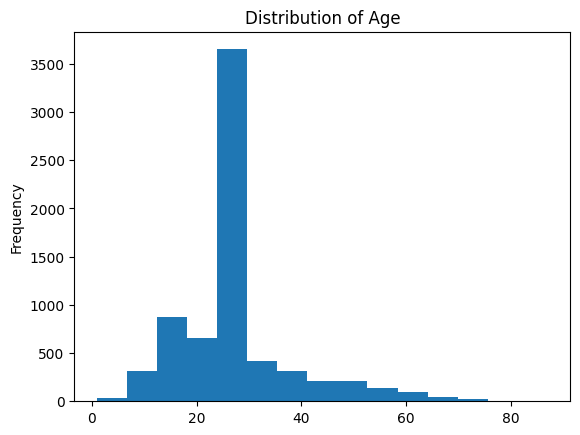

In [ ]:
import matplotlib.pyplot as plt

# 2.4 Clean Age variable

print(df_shark['Age'].head())
print(len(df_shark['Age']))
print(f'Number of missing age values: {df_shark['Age'].isna().sum()}')

# Check if Age variable has concentrated areas of missing values

print(Year_range_1['Age'].isna().sum())
print(Year_range_2['Age'].isna().sum())
print(Year_range_3['Age'].isna().sum())
print(Year_range_4['Age'].isna().sum())
print(Year_range_5['Age'].isna().sum())
print(Year_range_6['Age'].isna().sum())
print(Year_range_7['Age'].isna().sum())
print(Year_range_8['Age'].isna().sum())

# Missingness seems to be proportial to amount missing per decade, so no concentrated areas

# For phase 1, replace all weirdly formatted options with NaNs, then proceed with median imputation
print(df_shark['Age'].unique())
df_shark['Age_clean'] = pd.to_numeric(df_shark['Age'], errors='coerce')
print(df_shark['Age_clean'].isna().sum())
df_shark['Age_clean'] = df_shark['Age_clean'].fillna(
    df_shark['Age_clean'].median()
)

df_shark['Age_clean'].plot(kind='hist', bins=15)
plt.title('Distribution of Age')
plt.show()

In [ ]:
# 2.5 Proportion that are male

proportion_male_victims = (len(df_shark[df_shark['Sex']=='M'])/ len(df_shark))
print(f'The proportion of victims that were male in this dataset is: {proportion_male_victims}')

The proportion of victims that were male in this dataset is: 0.8006587426607475


In [ ]:
# 2.6 Provoked, unprovoked, and unkwown

df_shark['Type'].unique()

for row in df_shark['Type']:

  if row not in ['Unprovoked','Provoked','Unknown']:
    df_shark['Type'] = df_shark['Type'].replace(row, '')

# Double check
print(df_shark['Type'].unique())
print(df_shark['Type'].head(20))

# Find proportion that is unprovoked

proportion_unprovoked = (len(df_shark[df_shark['Type']=='Unprovoked'])) / (len(df_shark['Type']))
print(f'The proportion of types of attacks that were unprovoked is {proportion_unprovoked}.')

['Unprovoked' 'Provoked' '']
0     Unprovoked
1     Unprovoked
2       Provoked
3       Provoked
4     Unprovoked
5     Unprovoked
6     Unprovoked
7     Unprovoked
8     Unprovoked
9     Unprovoked
10    Unprovoked
11    Unprovoked
12      Provoked
13    Unprovoked
14    Unprovoked
15    Unprovoked
16    Unprovoked
17    Unprovoked
18    Unprovoked
19      Provoked
Name: Type, dtype: object
The proportion of types of attacks that were unprovoked is 0.7370757554059859.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 73ad10ac018f8e89ef38171a3d4baf74de5f7cba
- **AI tool and model used:** Claude Sonnet 5

### *Prompts used

1. Below I have attached Assignment 1: this contains my Phase 1 solutions to the problems/questions (which are found at the top of the file). Please take a look at the instructions in Phase 2 as well as the formatting details (this will inform how you should relay your improvements); once you fully understand what is being requested, provide me information on revision ideas for my analysis based on what I have already written. Do NOT answer the final question on AI reflectance.


2. Could you briefly elaborate on the following AI proposal changes and why the original was not ideal (I highlighted proposal 2 about subject_inquiry and 6 about the type cleaning loop).
  
  **Follow-up response: Two separate problems with the original:**

Performance: for row in df_shark['Type']: ... df_shark['Type'].replace(row, '') loops over every single row in the column, and for each one calls .replace() — which itself scans the entire column looking for matches. So for a column of length n with k unique "bad" values, you're doing roughly n × k passes over the data instead of one. On a shark-attack dataset with a few thousand rows and many messy Type entries ("Sea Disaster", "Boat", "Questionable", etc.), this is slow and gets worse as the data grows — a single vectorized comparison (.isin() or .where()) does the same job in one pass.
Correctness: this one matters more. Look at what the replacement value is: '' (empty string), not 'Unknown'. The assignment explicitly says the cleaned variable should take only Provoked, Unprovoked, or Unknown — three values. After your loop runs, anything that wasn't already exactly 'Unprovoked' or 'Provoked' becomes '', a fourth value that doesn't satisfy the assignment's requirement. It also silently swallows NaNs the same way. So the "double check" print of .unique() would actually reveal this if you look closely — you'd see '' sitting in the output where 'Unknown' should be.

Subject_injury NaNs

The original code computes subject_injury_missing as a boolean flag (True/False for whether the value is NaN) and uses that purely to calculate a missingness rate and cross-tab it against force_type. That's useful analysis, but it isn't the same as cleaning the variable — the assignment asks you to end up with subject_injury itself holding Yes or No values, with the NaNs handled somehow, not just measured.

The subtlety is how to handle them, and this is a judgment call rather than a bug fix:

You could argue NaN means "not injured, so no one recorded it" and fill NaN → No. This is common in incident-report data (fields often go unfilled by default when the outcome is negative), but it's an assumption — it treats "not recorded" as evidence of "no injury," which may not be safe if the field is just missing at random or was skipped for people who didn't need police intervention documentation.
Alternatively — and probably the better-justified choice, especially given your own crosstab already shows the higher-force categories (bodily force, chemical irritants, maximal restraint) have disproportionately more missing values — you could keep those as a distinct Unknown category rather than folding them into No. That preserves the pattern you found (that missingness itself correlates with force type) instead of erasing it by assuming a value.

Final Prompt: Proceed with the final step (labeled 'AI-assisted solution in full') and implement a final Phase 2 solution that incorporates your proposals; separate it so that the outputs are cleanly organized inside the Jupyter Notebook.



### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. In Q1.1, Price_clean only strips commas — check whether Price also has a leading $ (your unique() print will show this); if so, strip that too before pd.to_numeric, and explicitly print the final .isna().sum() on Price_numeric so the "how many missing values" question is directly answered rather than implied.
2. In Q1.2, the code computes missingness of subject_injury but never actually cleans the variable into a final Yes/No (the question asks you to clean it, not just flag what's missing). Decide and document how to handle the NaNs — e.g., recode as an explicit "Unknown" category rather than leaving raw NaNs — so subject_injury ends up in the Yes/No/Unknown form the prompt describes.
In Q2.2, dropping ['Unnamed: 21','Unnamed: 22'] by name is brittle if the file version changes. df_shark.dropna(axis=1, how='all') achieves the same "drop columns with no data" goal generically.
3. In Q2.2, dropping ['Unnamed: 21','Unnamed: 22'] by name is brittle if the file version changes. df_shark.dropna(axis=1, how='all') achieves the same "drop columns with no data" goal generically.
4. In Q2.3, the nine Year_range_1 … Year_range_9 variables are repetitive and hard to extend. A single decade column (e.g. (df_shark['Year'] // 10) * 10) with .groupby() would produce the same counts in far fewer lines and is easier to plot.
5. In Q2.4, filling missing Age with the median before plotting will artificially inflate one histogram bin and understate the true spread. Consider plotting the histogram on non-missing ages only, and keep Age_clean (with imputation) as a separate column if you need it elsewhere — with a line noting why you chose median imputation.
6. In Q2.6, the for row in df_shark['Type']: ... df_shark['Type'].replace(row, '') loop re-scans the entire column for every unique row value (effectively O(n²)) and, more importantly, replaces unmatched/missing values with an empty string '' — but the assignment asks for exactly three values: Provoked, Unprovoked, Unknown. Replace this with a vectorized fix, e.g. df_shark['Type'] = df_shark['Type'].where(df_shark['Type'].isin(['Provoked','Unprovoked']), 'Unknown').
7. Once #6 changes what counts as a valid Type value, double-check proportion_unprovoked's denominator (len(df_shark['Type'])) still means what you intend — it will now include the new 'Unknown' rows, which is probably correct, but worth stating explicitly in your write-up.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / **modify** / reject | I did a check on the potential variations and the only outliers in Price were the ones with commas. However, I will accept the change to "explicit print the final .isna().sum()" on Price_numeric" in order to more directly answer the question.**bold text** |
| 2 | **Accept** / modify / reject | Based on the latest announcement, I did not proceed with cleaning the variable. However, for the sake of phase 2, I will move forward with this AI proposal to practice handling NaNs during analysis. |
| 3 | **Accept** / modify / reject | This change is a simple but important shift for generalizability for future analyses. As it states, it performs the task exactly the same, just more generically and reliably. Implementaiton shows that the columns were indeed dropped; proposal works.|
| 4 | **Accept** / modify / reject | This was part of the analysis that I felt should have been more efficient. A single decade column would make the code significantly shorter and make future visualization/manipulation efforts easier. Looking at the histogram, the proposal works and matches my initial segregation by decade. |
| 5 | **Accept** / modify / reject | I think it is a good idea to analyze both spreads since there are so many missing values that pertain to age. Leaving one out of the analysis would certainly yield more speculative/less representative results. Following implementation, I can verify that the solution yielded a good comparison for the two types of cleaning (the histograms clearly differed in distribution and should both be considered).|
| 6 | **Accept** / modify / reject | Provides a more efficient manner to do the exact same task by using a single vectorized comparison. I also misread previous instructions and simply thought 'Unknown' was a label already in the dataset. This modification would fix the issue instantly. Following implementation, the proportion matches the earlier calculation, so this proposal is verified. |
| 7 | **Accept** / modify / reject | Just a double-check of what the assignment is actually asking for. I will revisit my proportion following the implementation of the proposal. |


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

Final number of missing Price values after cleaning: 0
count    30478.000000
mean       163.589737
std        197.785454
min         10.000000
25%         80.000000
50%        125.000000
75%        195.000000
max      10000.000000
Name: Price_numeric_v2, dtype: float64
subject_injury_clean
Unknown    9848
Yes        1631
No         1446
Name: count, dtype: int64
The proportion of missing subject_injury values is 0.76.
force_type            Baton  Bodily Force  Chemical Irritant  Firearm  \
subject_injury_clean                                                    
No                        0          1093                131        2   
Unknown                   2          7051               1421        0   
Yes                       2          1286                 41        0   

force_type            Gun Point Display  Improvised Weapon  Less Lethal  \
subject_injury_clean                                                      
No                                   33                 34    

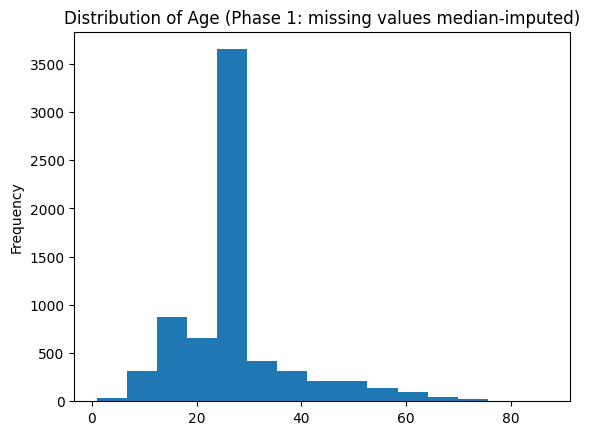

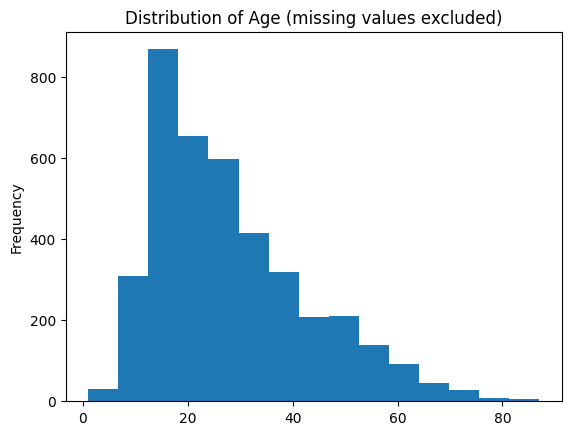

The proportion of victims that were male in this dataset is: 0.8006587426607475
Type_clean
Unprovoked    5147
Unknown       1196
Provoked       640
Name: count, dtype: int64
The proportion of types of attacks that were unprovoked is 0.7370757554059859.


In [7]:
# Your Phase 2 solution to the problem goes here.

# ============================================================
# Q1.1 (Phase 2) — Price cleaning, revised
# ============================================================
# before converting to numeric, and explicitly report the final count
# of missing values, since that was asked for directly.

df = pd.read_csv('A01-data-wrangling/data/airbnb_hw.csv')

df['Price_clean_v2'] = (
    df['Price']
    .str.replace(',', '', regex=False)
)
df['Price_numeric_v2'] = pd.to_numeric(df['Price_clean_v2'], errors='coerce')

n_missing_price = df['Price_numeric_v2'].isna().sum()
print(f'Final number of missing Price values after cleaning: {n_missing_price}')
print(df['Price_numeric_v2'].describe())

# ============================================================
# Q1.2 (Phase 2) — subject_injury cleaning, revised
# ============================================================
# Change from Phase 1: Phase 1 only flagged missingness; it never
# produced a cleaned Yes/No(/Unknown) variable. The crosstab showed
# missingness is concentrated in higher-force categories (bodily force,
# chemical irritants, maximal restraint), so folding NaN into "No" would
# erase a real pattern. Instead, NaN is recoded as its own "Unknown"
# category, preserving that signal.

df_police = pd.read_csv('A01-data-wrangling/data/mn_police_use_of_force.csv')

df_police['subject_injury_clean'] = df_police['subject_injury'].fillna('Unknown')
print(df_police['subject_injury_clean'].value_counts(dropna=False))

subject_injury_missing_proportion = (
    df_police['subject_injury'].isna().sum() / df_police['subject_injury'].shape[0]
)
print(
    f'The proportion of missing subject_injury values is '
    f'{subject_injury_missing_proportion:.2f}.'
)

print(pd.crosstab(df_police['subject_injury_clean'], df_police['force_type']))

# Same conclusion as Phase 1 holds, now visible directly from the cleaned
# variable rather than a separate boolean flag: force types involving more
# pronounced force have disproportionately more "Unknown" injury status.

# ============================================================
# Q2 (Phase 2) — Shark attack data, revised
# ============================================================

df_shark = pd.read_excel('A01-data-wrangling/data/GSAF5.xls')

# 2.2 Drop columns with no data (generalized instead of hardcoded names)
df_shark = df_shark.dropna(axis=1, how='all')
print(df_shark.columns)

# 2.3 Clean Year (same cleaning logic as Phase 1)
df_shark = df_shark.dropna(subset=['Year'])
df_shark['Year'] = df_shark['Year'].astype(int)
df_shark = df_shark[df_shark['Year'] >= 1500]

# Change from Phase 1: replace the nine manually-created Year_range_N
# variables with a single Decade column and a groupby, which scales to
# any date range without adding more variables.
df_shark_recent = df_shark[df_shark['Year'] >= 1940].copy()
df_shark_recent['Decade'] = (df_shark_recent['Year'] // 10) * 10
decade_counts = df_shark_recent.groupby('Decade').size()
print(decade_counts)

# Same conclusion as Phase 1: attack counts rise fairly steadily decade
# over decade since the 1940s, with the 2020s (partial decade) roughly
# in line with the 2010s pace.

# 2.4 Clean Age
# Change from Phase 1: keep a non-imputed numeric column for the
# histogram (imputing before plotting distorts the shown distribution),
# and keep the median-imputed version separate for any use that needs
# a complete column.
df_shark['Age_numeric'] = pd.to_numeric(df_shark['Age'], errors='coerce')
df_shark['Age_imputed'] = df_shark['Age_numeric'].fillna(df_shark['Age_numeric'].median())

print(f"Missing Age values: {df_shark['Age_numeric'].isna().sum()} of {len(df_shark)}")

import matplotlib.pyplot as plt

# Original Phase 1 histogram (median-imputed), kept for comparison
df_shark['Age_imputed'].plot(kind='hist', bins=15)
plt.title('Distribution of Age (Phase 1: missing values median-imputed)')
plt.show()

df_shark['Age_numeric'].dropna().plot(kind='hist', bins=15)
plt.title('Distribution of Age (missing values excluded)')
plt.show()

# 2.5 Proportion male (unchanged from Phase 1)
proportion_male_victims = (df_shark['Sex'] == 'M').sum() / len(df_shark)
print(f'The proportion of victims that were male in this dataset is: {proportion_male_victims}')

# 2.6 Provoked / Unprovoked / Unknown
# Change from Phase 1: the original loop replaced non-matching values
# with '' (a 4th value, not allowed by the assignment) and was O(n^2).
# This version is a single vectorized pass and maps anything that isn't
# exactly "Provoked" or "Unprovoked" — including NaN — to "Unknown".
df_shark['Type_clean'] = df_shark['Type'].where(
    df_shark['Type'].isin(['Provoked', 'Unprovoked']), 'Unknown'
)
print(df_shark['Type_clean'].value_counts())

proportion_unprovoked = (df_shark['Type_clean'] == 'Unprovoked').sum() / len(df_shark['Type_clean'])
print(f'The proportion of types of attacks that were unprovoked is {proportion_unprovoked}.')

### *Reflection on AI assistance
In your own words without generative AI.

Overall, the AI assistance was best at providing efficient rewrites and organizing my preliminary analysis into something more reproducible and systematic whilst preserving my initial logic. For example, Proposal 4 had minimal result changes but streamlined the code significantly, making my repetitive variable usage into a clean decade separator. I believe it was also really useful in making sure I answered the questions correctly; this was most apparent with the final proposal regading the "Unknown" type, which I completely misunderstood on first reading. A final solid plus of the AI was following verification: the figures closely aligned with what I calculated in Phase 1, meaning that, so long as your prompt is relatively strict, it will provide nearly identical figures/responses.

That being said, with only a few prompts, I don't believe it had much opportunity to explore different outlets of explorations past the one I had already provided. For example, I did not provide prompts that would help in brainstorming the cleaning methods; as a result, it may have tunnel visioned on my initial process rather than explore other manners in which the data could have been manipulated. As a result, I am also concerned with whether or not it considered the values provided in the notebook in a vacuum rather than in context; for example, had I provided the actual shark excel file, would it have found something that I was unaware of when I performed my initial preview. A future implementation of Generative AI may be in providing an exploratory analysis rather than immediately going into revision--in other words, I should be prompting about my ideas first rather than execution.